In [82]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
from scipy.special import erfcinv
import random
import seaborn as sns
from scipy.stats import norm
import glob
import seaborn as sns
import logging
from pathlib import Path
from scipy.ndimage import label as cc_label
from tqdm import tqdm
import pyarrow as pa
import pyarrow.parquet as pq
from scipy.stats import norm

# Base familiarity

In [ ]:
# read in files from ilt parquet
files = glob.glob('/home/sayakdg/ILIWorkflows/workflows/corrosion_detection/data-files/0AXVHCA77S1/corrosion_detection/corrosion_v4.2/track_00/01-000-1B3U2QML/0/*parquet')

In [ ]:
# look at one of these parquets
df_trial_1 = pd.read_parquet(files[0])
df_trial_1

In [ ]:
# look at another one of these parquets
df_trial_2 = pd.read_parquet(files[1])
df_trial_2

In [ ]:
fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), sharex=True)
# ax1.plot(df_trial_1.query('id_corro_prob > 0.05')['id_corro_prob'], label="Raw probs from first few frames", color="red", alpha=0.7)
ax1.plot(df_trial_2.query('id_corro_prob > 0.0005')['id_corro_prob'], label="Raw probs from first few frames", color="blue", alpha=0.7)

In [ ]:
# grouped dataframe

df_grp = pd.read_parquet('/home/sayakdg/ILIWorkflows/workflows/corrosion_detection/data-files/0AXVHCA77S1/corrosion_detection/corrosion_v4.2/grouping/corrosion_v4.2_grouped.parquet')
df_grp

In [ ]:
fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), sharex=True)
ax1.plot(df_grp['start_frame_idx'], label="Raw probs from first few frames", color="red", alpha=0.7)

In [ ]:
# apply a full grouping algorithm per track with a low prob threshold cutoff
files = glob.glob('/home/sayakdg/ILIWorkflows/workflows/corrosion_detection/data-files/0AXVHCA77S1/'
                'corrosion_detection/corrosion_v4.2/track_01/*/0/*parquet')
trackDF = pd.DataFrame({})
min_thresh: float=0.01
for file in files:
    df = pd.read_parquet(file)
    df = df.query('id_corro_prob >= @min_thresh').reset_index(drop = True)
    print('Length of data frame getting joined:',len(df))
    trackDF = pd.concat([trackDF,df])

In [ ]:
trackDF['frame_idx'] = trackDF['frame_idx']/(1e8)

In [ ]:
fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), sharex=True)
sns.lineplot(data=trackDF.query('frame_idx < 0.0001'), x="frame_idx", y="id_corro_prob")

# Sieving to get local peaks

In [50]:
files_track_0 = glob.glob('/home/sayakdg/ILIWorkflows/workflows/corrosion_detection/data-files/0AXVHCA77S1/corrosion_detection/corrosion_v4.2/track_19/*/0/*parquet')
full_df = pd.read_parquet(files_track_0[14])
full_df = full_df.sort_values("frame_idx").reset_index(drop=True)

<Axes: xlabel='frame_idx', ylabel='id_corro_prob'>

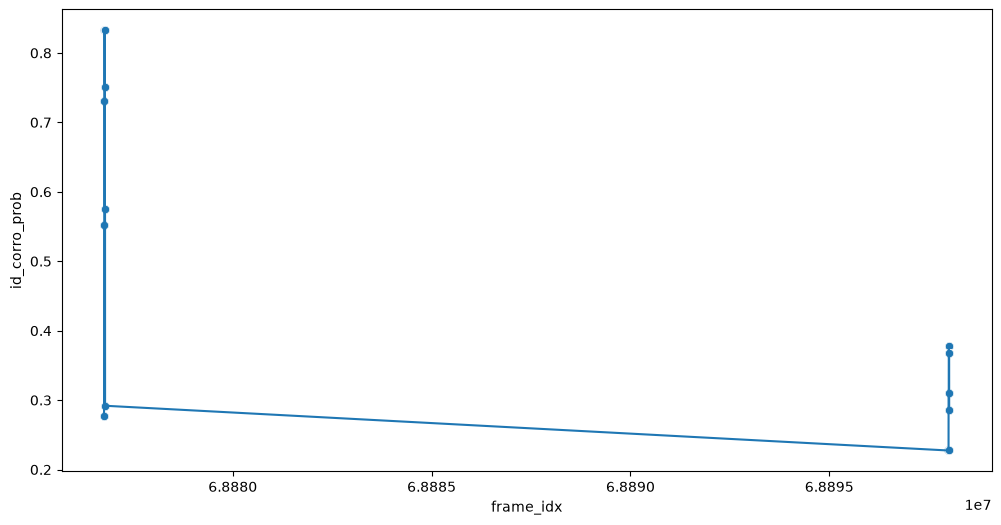

In [67]:
fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), sharex=True)
sns.lineplot(data=full_df.query('id_corro_prob > 0.2'), x="frame_idx", y="id_corro_prob")
sns.scatterplot(data=full_df.query('id_corro_prob > 0.2'), x="frame_idx", y="id_corro_prob")

## How the grouping works 

The grouping algorithm is applied per clip segment not for the whole track together.

In [53]:
files_track_0 = glob.glob('/home/sayakdg/ILIWorkflows/workflows/corrosion_detection/data-files/0AXVHCA77S1/corrosion_detection/corrosion_v4.2/track_19/*/0/*parquet')
full_df = pd.read_parquet(files_track_0[14]) #looking at 14th parquet in track 19
full_df = full_df.sort_values("frame_idx").reset_index(drop=True)

In [58]:
GROUPING_THRESHOLD = 0.5
FILTER_THRESHOLD = 0.7
MIN_FRAMES = 5
MAX_FRAMES = 10


frame = full_df["frame_idx"].to_numpy()
odo = full_df["odometer_tick"].to_numpy()
prob = full_df['id_corro_prob'].to_numpy(dtype=float)

full_seg_filt_df = full_df.query('id_corro_prob >= @GROUPING_THRESHOLD').reset_index(drop=True) # this the basic first filter
full_seg_filt_df

,inspection_id,clip_id,track_id,frame_idx,timer_tick,odometer_tick,id_corro_prob
0,0AXVHCA77S1,01-019-1B3U3DF1,19,68876764,2457879334,1246239300,0.551641
1,0AXVHCA77S1,01-019-1B3U3DF1,19,68876765,2457879382,1246239318,0.551641
2,0AXVHCA77S1,01-019-1B3U3DF1,19,68876766,2457879430,1246239336,0.551641
3,0AXVHCA77S1,01-019-1B3U3DF1,19,68876767,2457879478,1246239354,0.551641
4,0AXVHCA77S1,01-019-1B3U3DF1,19,68876768,2457879527,1246239372,0.551641
5,0AXVHCA77S1,01-019-1B3U3DF1,19,68876769,2457879626,1246239408,0.730637
6,0AXVHCA77S1,01-019-1B3U3DF1,19,68876770,2457879677,1246239426,0.730637
7,0AXVHCA77S1,01-019-1B3U3DF1,19,68876771,2457879726,1246239444,0.730637
8,0AXVHCA77S1,01-019-1B3U3DF1,19,68876772,2457879777,1246239462,0.730637
9,0AXVHCA77S1,01-019-1B3U3DF1,19,68876773,2457879827,1246239480,0.730637


In [60]:
# label groups by cont frames at this time the large 
resets = full_seg_filt_df['frame_idx'].diff() != 1
resets.iloc[0] = False
full_seg_filt_df['group_id'] = resets.cumsum()


# filter small groups:
groups = full_seg_filt_df['group_id'].unique()
group_count_df = full_seg_filt_df[['inspection_id','group_id']].groupby('group_id').count().reset_index()
good_grps = group_count_df.query('inspection_id >= @MIN_FRAMES')['group_id'].unique()
full_seg_filt_df = full_seg_filt_df.query('group_id in @good_grps')

full_seg_filt_df

,inspection_id,clip_id,track_id,frame_idx,timer_tick,odometer_tick,id_corro_prob,group_id
0,0AXVHCA77S1,01-019-1B3U3DF1,19,68876764,2457879334,1246239300,0.551641,0
1,0AXVHCA77S1,01-019-1B3U3DF1,19,68876765,2457879382,1246239318,0.551641,0
2,0AXVHCA77S1,01-019-1B3U3DF1,19,68876766,2457879430,1246239336,0.551641,0
3,0AXVHCA77S1,01-019-1B3U3DF1,19,68876767,2457879478,1246239354,0.551641,0
4,0AXVHCA77S1,01-019-1B3U3DF1,19,68876768,2457879527,1246239372,0.551641,0
5,0AXVHCA77S1,01-019-1B3U3DF1,19,68876769,2457879626,1246239408,0.730637,0
6,0AXVHCA77S1,01-019-1B3U3DF1,19,68876770,2457879677,1246239426,0.730637,0
7,0AXVHCA77S1,01-019-1B3U3DF1,19,68876771,2457879726,1246239444,0.730637,0
8,0AXVHCA77S1,01-019-1B3U3DF1,19,68876772,2457879777,1246239462,0.730637,0
9,0AXVHCA77S1,01-019-1B3U3DF1,19,68876773,2457879827,1246239480,0.730637,0


In [61]:
# Split groups longer than MAX_FRAMES note that there is no physics built into this cutoff, we can argue that this should be the median size of defects
full_seg_filt_df['sub_group'] = full_seg_filt_df.groupby('group_id').cumcount() // MAX_FRAMES
# 3. Create a unique identifier by combining both columns
full_seg_filt_df['final_group'] = full_seg_filt_df['group_id'].astype(str) + "_" + full_seg_filt_df['sub_group'].astype(str)
# Optional: Convert the combined IDs back to clean, sequential integers (0, 1, 2...)
full_seg_filt_df['final_group_id'] = pd.factorize(full_seg_filt_df['final_group'])[0]
full_seg_filt_df.drop(columns = ['sub_group','final_group'],inplace = True)

full_seg_filt_df

,inspection_id,clip_id,track_id,frame_idx,timer_tick,odometer_tick,id_corro_prob,group_id,final_group_id
0,0AXVHCA77S1,01-019-1B3U3DF1,19,68876764,2457879334,1246239300,0.551641,0,0
1,0AXVHCA77S1,01-019-1B3U3DF1,19,68876765,2457879382,1246239318,0.551641,0,0
2,0AXVHCA77S1,01-019-1B3U3DF1,19,68876766,2457879430,1246239336,0.551641,0,0
3,0AXVHCA77S1,01-019-1B3U3DF1,19,68876767,2457879478,1246239354,0.551641,0,0
4,0AXVHCA77S1,01-019-1B3U3DF1,19,68876768,2457879527,1246239372,0.551641,0,0
5,0AXVHCA77S1,01-019-1B3U3DF1,19,68876769,2457879626,1246239408,0.730637,0,0
6,0AXVHCA77S1,01-019-1B3U3DF1,19,68876770,2457879677,1246239426,0.730637,0,0
7,0AXVHCA77S1,01-019-1B3U3DF1,19,68876771,2457879726,1246239444,0.730637,0,0
8,0AXVHCA77S1,01-019-1B3U3DF1,19,68876772,2457879777,1246239462,0.730637,0,0
9,0AXVHCA77S1,01-019-1B3U3DF1,19,68876773,2457879827,1246239480,0.730637,0,0


In [62]:
# label group by max prob in group and count the number of frames in that group and the sum of the probs
prob_max_df = full_seg_filt_df[['id_corro_prob','final_group_id']].groupby('final_group_id').agg(['max','count','sum']).reset_index()
prob_max_df.columns = ['_'.join(col) for col in prob_max_df.columns]
prob_max_df.rename(columns={'final_group_id_':'final_group_id'},inplace = True)
full_seg_filt_df = full_seg_filt_df.merge(prob_max_df,left_on = 'final_group_id', right_on = 'final_group_id').reset_index(drop = True)
full_seg_filt_df

,inspection_id,clip_id,track_id,frame_idx,timer_tick,odometer_tick,id_corro_prob,group_id,final_group_id,id_corro_prob_max,id_corro_prob_count,id_corro_prob_sum
0,0AXVHCA77S1,01-019-1B3U3DF1,19,68876764,2457879334,1246239300,0.551641,0,0,0.730637,10,6.411388
1,0AXVHCA77S1,01-019-1B3U3DF1,19,68876765,2457879382,1246239318,0.551641,0,0,0.730637,10,6.411388
2,0AXVHCA77S1,01-019-1B3U3DF1,19,68876766,2457879430,1246239336,0.551641,0,0,0.730637,10,6.411388
3,0AXVHCA77S1,01-019-1B3U3DF1,19,68876767,2457879478,1246239354,0.551641,0,0,0.730637,10,6.411388
4,0AXVHCA77S1,01-019-1B3U3DF1,19,68876768,2457879527,1246239372,0.551641,0,0,0.730637,10,6.411388
5,0AXVHCA77S1,01-019-1B3U3DF1,19,68876769,2457879626,1246239408,0.730637,0,0,0.730637,10,6.411388
6,0AXVHCA77S1,01-019-1B3U3DF1,19,68876770,2457879677,1246239426,0.730637,0,0,0.730637,10,6.411388
7,0AXVHCA77S1,01-019-1B3U3DF1,19,68876771,2457879726,1246239444,0.730637,0,0,0.730637,10,6.411388
8,0AXVHCA77S1,01-019-1B3U3DF1,19,68876772,2457879777,1246239462,0.730637,0,0,0.730637,10,6.411388
9,0AXVHCA77S1,01-019-1B3U3DF1,19,68876773,2457879827,1246239480,0.730637,0,0,0.730637,10,6.411388


In [63]:
# begin and end of frames and odometer ticks
loc_df = full_seg_filt_df[['frame_idx','odometer_tick','final_group_id']].groupby('final_group_id').agg(['max','min']).reset_index()
loc_df.columns = ['_'.join(col) for col in loc_df.columns]
loc_df.rename(columns={'final_group_id_':'final_group_id'},inplace = True)
full_seg_filt_df = full_seg_filt_df.merge(loc_df,left_on = 'final_group_id', right_on = 'final_group_id').reset_index(drop = True)

# drop group if group threshold is not met and number of frames are below min frames
full_seg_filt_df = full_seg_filt_df.query('id_corro_prob_max >= @FILTER_THRESHOLD and id_corro_prob_count >= @MIN_FRAMES').reset_index(drop = True)

full_seg_filt_df

,inspection_id,clip_id,track_id,frame_idx,timer_tick,odometer_tick,id_corro_prob,group_id,final_group_id,id_corro_prob_max,id_corro_prob_count,id_corro_prob_sum,frame_idx_max,frame_idx_min,odometer_tick_max,odometer_tick_min
0,0AXVHCA77S1,01-019-1B3U3DF1,19,68876764,2457879334,1246239300,0.551641,0,0,0.730637,10,6.411388,68876773,68876764,1246239480,1246239300
1,0AXVHCA77S1,01-019-1B3U3DF1,19,68876765,2457879382,1246239318,0.551641,0,0,0.730637,10,6.411388,68876773,68876764,1246239480,1246239300
2,0AXVHCA77S1,01-019-1B3U3DF1,19,68876766,2457879430,1246239336,0.551641,0,0,0.730637,10,6.411388,68876773,68876764,1246239480,1246239300
3,0AXVHCA77S1,01-019-1B3U3DF1,19,68876767,2457879478,1246239354,0.551641,0,0,0.730637,10,6.411388,68876773,68876764,1246239480,1246239300
4,0AXVHCA77S1,01-019-1B3U3DF1,19,68876768,2457879527,1246239372,0.551641,0,0,0.730637,10,6.411388,68876773,68876764,1246239480,1246239300
5,0AXVHCA77S1,01-019-1B3U3DF1,19,68876769,2457879626,1246239408,0.730637,0,0,0.730637,10,6.411388,68876773,68876764,1246239480,1246239300
6,0AXVHCA77S1,01-019-1B3U3DF1,19,68876770,2457879677,1246239426,0.730637,0,0,0.730637,10,6.411388,68876773,68876764,1246239480,1246239300
7,0AXVHCA77S1,01-019-1B3U3DF1,19,68876771,2457879726,1246239444,0.730637,0,0,0.730637,10,6.411388,68876773,68876764,1246239480,1246239300
8,0AXVHCA77S1,01-019-1B3U3DF1,19,68876772,2457879777,1246239462,0.730637,0,0,0.730637,10,6.411388,68876773,68876764,1246239480,1246239300
9,0AXVHCA77S1,01-019-1B3U3DF1,19,68876773,2457879827,1246239480,0.730637,0,0,0.730637,10,6.411388,68876773,68876764,1246239480,1246239300


In [64]:
#  final beautification

full_seg_filt_df.rename(
    columns={
         'frame_idx_min':'start_frame_idx',
         'frame_idx_max':'end_frame_idx',
         'odometer_tick_min':'start_odo_ticks',
         'odometer_tick_max':'end_odo_ticks',
         'id_corro_prob_max':'vol_conf',
         'id_corro_prob_sum':'total_vol_prob',
         'id_corro_prob_count':'length'},inplace = True)

full_seg_filt_df.drop(columns=['inspection_id','group_id','frame_idx', 'timer_tick','odometer_tick'], inplace=True)
full_seg_filt_df.drop_duplicates(subset=['final_group_id'], inplace=True)

full_seg_filt_df = full_seg_filt_df[['clip_id','track_id','final_group_id','start_odo_ticks', 'end_odo_ticks', 'start_frame_idx',
       'end_frame_idx', 'vol_conf','total_vol_prob', 'length']]

full_seg_filt_df

,clip_id,track_id,final_group_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,total_vol_prob,length
0,01-019-1B3U3DF1,19,0,1246239300,1246239480,68876764,68876773,0.730637,6.411388,10
10,01-019-1B3U3DF1,19,1,1246239498,1246239660,68876774,68876783,0.832316,7.914489,10


### The function itself in one

In [4]:
def grouping(full_seg_df,GROUPING_THRESHOLD,FILTER_THRESHOLD,MIN_FRAMES,MAX_FRAMES):
    try:
        frame = full_seg_df["frame_idx"].to_numpy()
        odo = full_seg_df["odometer_tick"].to_numpy()
        prob = full_seg_df['id_corro_prob'].to_numpy(dtype=float)
        
        full_seg_filt_df = full_seg_df.query('id_corro_prob >= @GROUPING_THRESHOLD').reset_index(drop=True)
        
        # fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), sharex=True)
        # sns.lineplot(data=full_seg_filt_df, x="frame_idx", y="id_corro_prob")
        
        # label groups by cont frames
        resets = full_seg_filt_df['frame_idx'].diff() != 1
        resets.iloc[0] = False
        full_seg_filt_df['group_id'] = resets.cumsum()
        
        # filter small groups:
        groups = full_seg_filt_df['group_id'].unique()
        group_count_df = full_seg_filt_df[['inspection_id','group_id']].groupby('group_id').count().reset_index()
        good_grps = group_count_df.query('inspection_id >= @MIN_FRAMES')['group_id'].unique()
        full_seg_filt_df = full_seg_filt_df.query('group_id in @good_grps')
        
        
        # Split groups longer than MAX_FRAMES
        full_seg_filt_df['sub_group'] = full_seg_filt_df.groupby('group_id').cumcount() // MAX_FRAMES
        # 3. Create a unique identifier by combining both columns
        full_seg_filt_df['final_group'] = full_seg_filt_df['group_id'].astype(str) + "_" + full_seg_filt_df['sub_group'].astype(str)
        # Optional: Convert the combined IDs back to clean, sequential integers (0, 1, 2...)
        full_seg_filt_df['final_group_id'] = pd.factorize(full_seg_filt_df['final_group'])[0]
        full_seg_filt_df.drop(columns = ['sub_group','final_group'],inplace = True)
        
        # label group by max prob in group and count the number of frames in that group and the sum of the probs
        prob_max_df = full_seg_filt_df[['id_corro_prob','final_group_id']].groupby('final_group_id').agg(['max','count','sum']).reset_index()
        prob_max_df.columns = ['_'.join(col) for col in prob_max_df.columns]
        prob_max_df.rename(columns={'final_group_id_':'final_group_id'},inplace = True)
        full_seg_filt_df = full_seg_filt_df.merge(prob_max_df,left_on = 'final_group_id', right_on = 'final_group_id').reset_index(drop = True)
        
        
        # begin and end of frames and odometer ticks
        loc_df = full_seg_filt_df[['frame_idx','odometer_tick','final_group_id']].groupby('final_group_id').agg(['max','min']).reset_index()
        loc_df.columns = ['_'.join(col) for col in loc_df.columns]
        loc_df.rename(columns={'final_group_id_':'final_group_id'},inplace = True)
        full_seg_filt_df = full_seg_filt_df.merge(loc_df,left_on = 'final_group_id', right_on = 'final_group_id').reset_index(drop = True)
    
        # drop group if group threshold is not met and number of frames are below min frames
        full_seg_filt_df = full_seg_filt_df.query('id_corro_prob_max >= @FILTER_THRESHOLD and id_corro_prob_count >= @MIN_FRAMES').reset_index(drop = True)
        
        full_seg_filt_df.rename(
            columns={
                 'frame_idx_min':'start_frame_idx',
                 'frame_idx_max':'end_frame_idx',
                 'odometer_tick_min':'start_odo_ticks',
                 'odometer_tick_max':'end_odo_ticks',
                 'id_corro_prob_max':'vol_conf',
                 'id_corro_prob_sum':'total_vol_prob',
                 'id_corro_prob_count':'length'},inplace = True)
        
        full_seg_filt_df.drop(columns=['inspection_id','group_id','frame_idx', 'timer_tick','odometer_tick'], inplace=True)
        full_seg_filt_df.drop_duplicates(subset=['final_group_id'], inplace=True)
        
        full_seg_filt_df = full_seg_filt_df[['clip_id','track_id','final_group_id','start_odo_ticks', 'end_odo_ticks', 'start_frame_idx',
               'end_frame_idx', 'vol_conf','total_vol_prob', 'length']]
        return full_seg_filt_df
    except:
        return pd.DataFrame(columns=['clip_id','track_id','final_group_id','start_odo_ticks', 'end_odo_ticks', 'start_frame_idx',
               'end_frame_idx', 'vol_conf','total_vol_prob', 'length'])

In [5]:
df1 = grouping(full_df,0.1,0.1,5,1000)
df2 = grouping(full_df,0.4,0.4,5,1000)

display(df1)
display(df2)

,clip_id,track_id,final_group_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,total_vol_prob,length
0,01-019-1B3U3DF1,19,0,1246239210,1246239840,68876759,68876793,0.832316,20.052181,35
35,01-019-1B3U3DF1,19,1,1246593786,1246593948,68896184,68896193,0.126557,1.164555,10
45,01-019-1B3U3DF1,19,2,1246626276,1246626888,68897989,68898023,0.377721,9.317684,35
80,01-019-1B3U3DF1,19,3,1246627266,1246627788,68898044,68898073,0.187826,4.700454,30
110,01-019-1B3U3DF1,19,4,1246630056,1246630398,68898199,68898218,0.136646,2.438952,20
130,01-019-1B3U3DF1,19,5,1246631046,1246631388,68898254,68898273,0.174794,3.076831,20


,clip_id,track_id,final_group_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,total_vol_prob,length
0,01-019-1B3U3DF1,19,0,1246239300,1246239750,68876764,68876788,0.832316,17.203605,25


In [65]:
# precursor to sequential filtering, apply sieves with increasing threshold and then collect them
bins = np.arange(0.2,1,0.1)
stackDF = pd.DataFrame()
for bi in bins:
    df = grouping(full_df,bi,bi,5,1000)
    if len(df) < 1:
        break
    else:
        df['bin_size'] = bi
        stackDF = pd.concat([stackDF,df]).reset_index(drop = True)

stackDF

,clip_id,track_id,final_group_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,total_vol_prob,length,bin_size
0,01-019-1B3U3DF1,19,0,1246239210,1246239840,68876759,68876793,0.832316,20.052181,35,0.2
1,01-019-1B3U3DF1,19,1,1246626366,1246626798,68897994,68898018,0.377721,7.842588,25,0.2
2,01-019-1B3U3DF1,19,0,1246239300,1246239750,68876764,68876788,0.832316,17.203605,25,0.3
3,01-019-1B3U3DF1,19,1,1246626456,1246626708,68897999,68898013,0.377721,5.277285,15,0.3
4,01-019-1B3U3DF1,19,0,1246239300,1246239750,68876764,68876788,0.832316,17.203605,25,0.4
5,01-019-1B3U3DF1,19,0,1246239300,1246239750,68876764,68876788,0.832316,17.203605,25,0.5
6,01-019-1B3U3DF1,19,0,1246239408,1246239660,68876769,68876783,0.832316,11.567674,15,0.6
7,01-019-1B3U3DF1,19,0,1246239408,1246239660,68876769,68876783,0.832316,11.567674,15,0.7
8,01-019-1B3U3DF1,19,0,1246239498,1246239570,68876774,68876778,0.832316,4.161580,5,0.8


# Sequential Filtering

In [66]:
# continue with the last stacked defect data frame we had in the last cell and apply the contains exclusion
# sequential filtering trials with a contains sieve. The code block at the bottom shows how contains works

# def keep_largest_nested_bins(df: pd.DataFrame) -> pd.DataFrame:
#     keep_mask = np.ones(len(df), dtype=bool)
#     for _, g in df.groupby(["clip_id", "track_id"], sort=False):
#         idx = g.index.to_numpy()
#         start = g["start_frame_idx"].to_numpy()
#         end = g["end_frame_idx"].to_numpy()
#         bins = g["bin_size"].to_numpy()
#         # pairwise: j contained in i, and bin_j > bin_i  => drop i
#         # shape: (n, n)
#         contained = (start[:, None] <= start[None, :]) & (end[None, :] <= end[:, None])
#         higher = bins[None, :] > bins[:, None]
#         # exclude self-comparisons
#         np.fill_diagonal(contained, False)
#         dominated = (contained & higher).any(axis=1)
#         keep_mask[idx[dominated]] = False
#     return df.loc[keep_mask].reset_index(drop=True)

start = stackDF["start_frame_idx"].to_numpy()
end = stackDF["end_frame_idx"].to_numpy()
bins = stackDF["bin_size"].to_numpy()
contained = (start[:, None] <= start[None, :]) & (end[None, :] <= end[:, None])
higher = bins[None, :] > bins[:, None]
np.fill_diagonal(contained, False)
dominated = (contained & higher).any(axis=1)
stackFiltDF = stackDF.loc[~dominated].reset_index(drop=True)

stackFiltDF

,clip_id,track_id,final_group_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,total_vol_prob,length,bin_size
0,01-019-1B3U3DF1,19,1,1246626456,1246626708,68897999,68898013,0.377721,5.277285,15,0.3
1,01-019-1B3U3DF1,19,0,1246239498,1246239570,68876774,68876778,0.832316,4.161580,5,0.8


In [10]:
# these functions are more compact implementations of the contains operation and deal with the situation where the overlapping regions are complete or none.
# In this case for the stacked implementation the complexity is of O(N) and not N^2

def keep_largest_nested_bins_laminar(df: pd.DataFrame) -> pd.DataFrame:
    if df.empty:
        return df.copy()

    order = np.lexsort((
        -df["end_frame_idx"].to_numpy(),
        df["start_frame_idx"].to_numpy(),
    ))
    end = df["end_frame_idx"].to_numpy()[order]
    bins = df["bin_size"].to_numpy()[order]

    dominated = np.zeros(len(order), dtype=bool)
    stack = []  # nested chain of sorted indices

    for j in range(len(order)):
        while stack and end[stack[-1]] < end[j]:
            stack.pop()  # no longer contains j

        for i in stack:
            if bins[i] < bins[j]:
                dominated[i] = True
            elif end[i] == end[j] and bins[i] > bins[j]:
                dominated[j] = True

        stack.append(j)

    return df.iloc[order[~dominated]].reset_index(drop=True)

def keep_largest_nested_bins_matrix(df):
    start = df["start_frame_idx"].to_numpy()
    end = df["end_frame_idx"].to_numpy()
    bins = df["bin_size"].to_numpy()
    contained = (start[:, None] <= start[None, :]) & (end[None, :] <= end[:, None])
    higher = bins[None, :] > bins[:, None]
    np.fill_diagonal(contained, False)
    dominated = (contained & higher).any(axis=1)
    return(df.loc[~dominated].reset_index(drop=True))

def overlap_check(df: pd.DataFrame) -> bool:
    # checks that the final data frames do not have overlapping frames
    start = df["start_frame_idx"].to_numpy()
    end = df["end_frame_idx"].to_numpy()
    bins = df["bin_size"].to_numpy()
    #  this is a nested containment matrix that marks every point where an interval is totally contained in another
    # N^2 operations so do not use with large matrices
    contained = (start[:, None] <= start[None, :]) & (end[None, :] <= end[:, None])
    arr = np.array(contained)
    # Create a mask where diagonal elements are False and non-diagonal are True
    non_diag_mask = ~np.eye(arr.shape[0], arr.shape[1], dtype=bool)
    non_diag_bool = np.any(arr[non_diag_mask])
    return non_diag_bool

In [68]:
# now we loop over every single parquet on a single track 
# 1. Gather all the parquets in the track
# 2. For each parquet apply the grouping at various thresholds
# 3. Follow this by the cascade
# 4. concat the cascaded thresholds into one dataframe for the whole track

files_track_0 = glob.glob('/home/sayakdg/ILIWorkflows/workflows/corrosion_detection/data-files/0AXVHCA77S1/corrosion_detection/corrosion_v4.2/track_19/*/0/*parquet')
# files_track_0 = [files_track_0[3]]
fullstackDF = pd.DataFrame()
fullStackFiltDF = pd.DataFrame()
for file in tqdm(files_track_0):
    fileDF = pd.read_parquet(file)
    bins = np.arange(0.2,1,0.1)
    stackDF = pd.DataFrame()
    for bi in bins:
        df = grouping(fileDF,bi,bi,5,1000)
        if len(df) < 1:
            break
        else:
            df['bin_size'] = bi
            stackDF = pd.concat([stackDF,df]).reset_index(drop = True)
    stackFiltDF = keep_largest_nested_bins_laminar(stackDF)
    fullstackDF = pd.concat([stackDF,fullstackDF]).reset_index(drop = True)
    fullStackFiltDF = pd.concat([stackFiltDF,fullStackFiltDF]).reset_index(drop = True)

fullStackFiltDF

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1934/1934 [01:03<00:00, 30.66it/s]


,clip_id,track_id,final_group_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,total_vol_prob,length,bin_size
0,01-019-1B3U3DF1,19,0,468045822,468046092,25872609,25872623,0.274269,3.755858,15,0.2
1,01-019-1B3U3DF1,19,0,1042329708,1042329870,57612679,57612688,0.879601,8.398128,10,0.8
2,01-019-1B3U3DF1,19,0,509336490,509336562,28154094,28154098,0.633602,3.168010,5,0.6
3,01-019-1B3U3DF1,19,1,509373588,509373930,28156124,28156143,0.397878,7.137096,20,0.3
4,01-019-1B3U3DF1,19,2,509374776,509375028,28156189,28156203,0.229800,3.278621,15,0.2
...,...,...,...,...,...,...,...,...,...,...,...
3065,01-019-1B3U3DF1,19,1,586880916,586881078,32439794,32439803,0.452268,4.468294,10,0.4
3066,01-019-1B3U3DF1,19,0,1740812982,1740813234,96201149,96201163,0.268336,3.710515,15,0.2
3067,01-019-1B3U3DF1,19,0,1255752690,1255752852,69401159,69401168,0.436214,4.282185,10,0.4
3068,01-019-1B3U3DF1,19,0,1256404932,1256405094,69437394,69437403,0.850511,8.461800,10,0.8


In [69]:
# check if there are overlaps in identified frame ranges within a clip 
unique_clips = fullStackFiltDF['clip_id'].unique()
print(unique_clips)
for clip in unique_clips:
    df = fullStackFiltDF.query('clip_id == @clip')
    print('For clip ',clip,' are there any overlapping segments:',overlap_check(df))

<ArrowStringArray>
['01-019-1B3U3DF1']
Length: 1, dtype: str
For clip  01-019-1B3U3DF1  are there any overlapping segments: False


<Axes: xlabel='bin_size', ylabel='Count'>

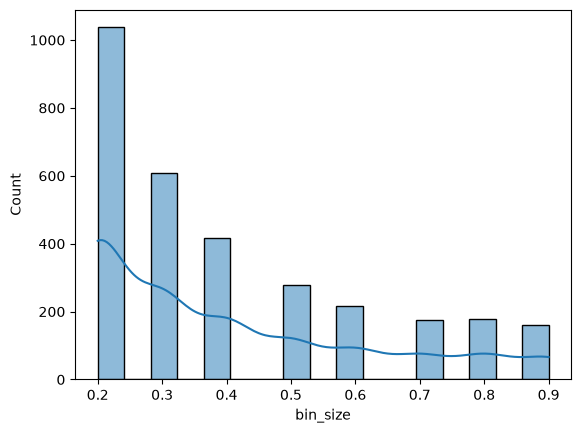

In [70]:
sns.histplot(data=fullStackFiltDF, x="bin_size", kde=True)

## Reading anomalies by local maximas

In [73]:
from scipy.signal import find_peaks

In [74]:
# locate the maximas, then collect the context by looking at two frames on either side 
# the bin for the maxima should be fixed at the ceil of the mean prob across that context

files_track_0 = glob.glob('/home/sayakdg/ILIWorkflows/workflows/corrosion_detection/data-files/0AXVHCA77S1/corrosion_detection/corrosion_v4.2/track_00/01-000-1B3U2QML/0/*parquet')
full_df = pd.read_parquet(files_track_0[3])
full_df = full_df.sort_values("frame_idx").reset_index(drop=True)
full_df = full_df.reset_index()

<Axes: xlabel='frame_idx', ylabel='id_corro_prob'>

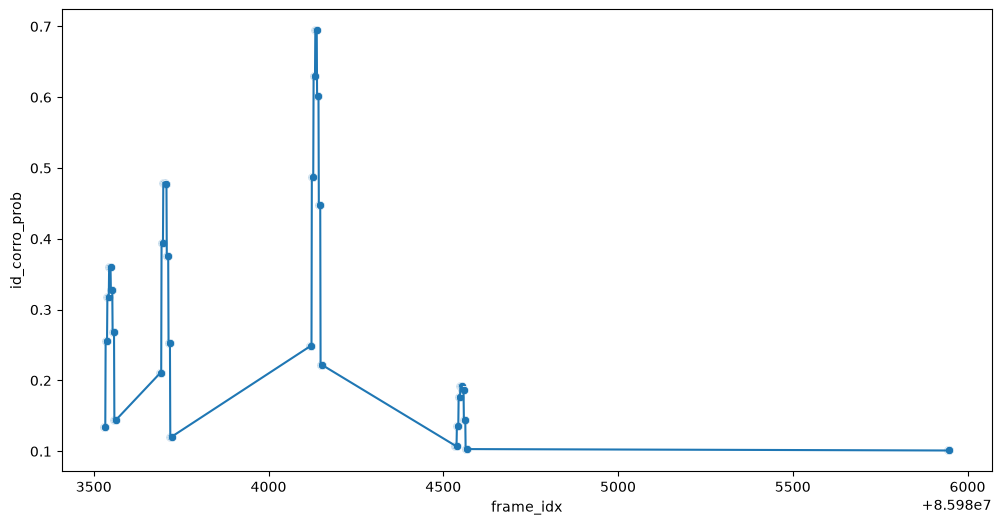

In [75]:
fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), sharex=True)
sns.lineplot(data=full_df.query('id_corro_prob >= 0.1'), x="frame_idx", y="id_corro_prob")
sns.scatterplot(data=full_df.query('id_corro_prob >= 0.1'), x="frame_idx", y="id_corro_prob")

Prominent peak indices: [33546 33701 34136 34551 35946]
Calculated prominences: [0.35728933 0.47886118 0.69405396 0.19142761 0.10057392]


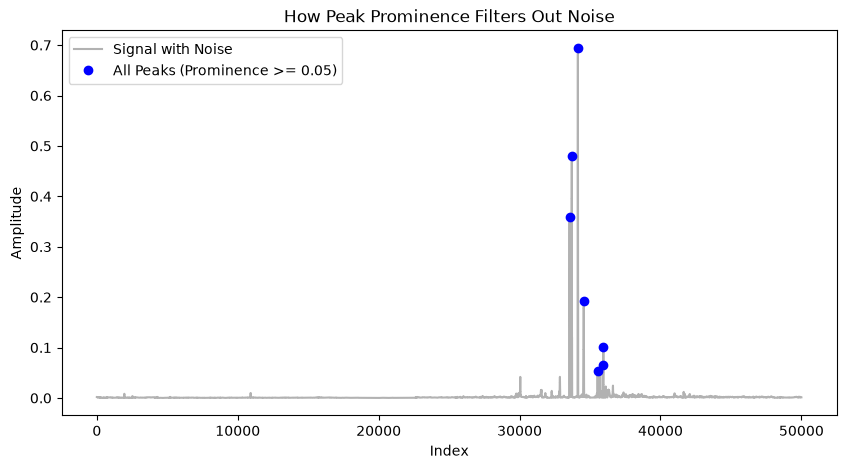

In [76]:
signal = full_df.query('id_corro_prob >= 0.00001')['id_corro_prob'].to_numpy()

# Case 1: Find all peaks without filtering (low prominence threshold)
all_peaks, _ = find_peaks(signal, prominence=0.05)

# Case 2: Filter for major peaks only (high prominence threshold)
prominent_peaks, properties = find_peaks(signal, prominence=0.1)

# Print the prominence values of the major peaks
print("Prominent peak indices:", prominent_peaks)
print("Calculated prominences:", properties["prominences"])

# Visual Comparison
plt.figure(figsize=(10, 5))
plt.plot(signal, label="Signal with Noise", color="gray", alpha=0.6)
plt.plot(all_peaks, signal[all_peaks], "o", label="All Peaks (Prominence >= 0.05)", color="blue")
# plt.plot(prominent_peaks, signal[prominent_peaks], "x", markersize=12, mew=3, label="Major Peaks (Prominence >= 0.6)", color="red")
plt.xlabel("Index")
plt.ylabel("Amplitude")
plt.legend()
plt.title("How Peak Prominence Filters Out Noise")
plt.show()

In [77]:
files_track_0 = glob.glob('/home/sayakdg/ILIWorkflows/workflows/corrosion_detection/data-files/0AXVHCA77S1/corrosion_detection/corrosion_v4.2/track_00/01-000-1B3U2QML/0/*parquet')
full_df = pd.read_parquet(files_track_0[3])
full_df = full_df.sort_values("frame_idx").reset_index(drop=True)
full_df = full_df.reset_index()

In [78]:
# do not do an initial filter ask for a prominence threshold of 0.1
signal = full_df.query('id_corro_prob >= 0.00001')['id_corro_prob'].to_numpy()
all_peaks, properties = find_peaks(signal, prominence=0.1)
peakDF = pd.DataFrame({'index':all_peaks,'peak_height':properties["prominences"]})

# merge back
full_df = full_df.merge(peakDF, left_on = 'index', right_on = 'index', how = 'outer').fillna({"peak_height": 0})
# display(full_df)
# display(full_df.query('peak_height > 0'))

# add the nearby locations to enable averaging
initial_arr = all_peaks
# Column-stack the mathematically shifted matrices and flatten
aug_all_peaks = np.column_stack((initial_arr - 3,initial_arr - 2,initial_arr - 1, initial_arr, initial_arr + 1,initial_arr + 2,initial_arr + 3)).flatten()
augDF = pd.DataFrame({'index':aug_all_peaks,'averager':np.ones(len(aug_all_peaks))})
full_df = full_df.merge(augDF, left_on = 'index', right_on = 'index', how = 'outer').fillna({"averager": 0})

full_df = full_df.query('averager > 0').reset_index(drop = True)
full_df.drop(columns=['averager'], inplace=True)

resets = full_df['frame_idx'].diff() != 1
resets.iloc[0] = False
full_df['group_id'] = resets.cumsum()

full_df

,index,inspection_id,clip_id,track_id,frame_idx,timer_tick,odometer_tick,id_corro_prob,peak_height,group_id
0,33543,0AXVHCA77S1,01-000-1B3U2QML,0,85983543,3303729866,1555578402,0.317704,0.000000,0
1,33544,0AXVHCA77S1,01-000-1B3U2QML,0,85983544,3303729911,1555578420,0.359642,0.000000,0
2,33545,0AXVHCA77S1,01-000-1B3U2QML,0,85983545,3303729957,1555578438,0.359642,0.000000,0
3,33546,0AXVHCA77S1,01-000-1B3U2QML,0,85983546,3303730006,1555578456,0.359642,0.357289,0
4,33547,0AXVHCA77S1,01-000-1B3U2QML,0,85983547,3303730052,1555578474,0.359642,0.000000,0
5,33548,0AXVHCA77S1,01-000-1B3U2QML,0,85983548,3303730100,1555578492,0.359642,0.000000,0
6,33549,0AXVHCA77S1,01-000-1B3U2QML,0,85983549,3303730148,1555578510,0.328036,0.000000,0
7,33698,0AXVHCA77S1,01-000-1B3U2QML,0,85983698,3303737410,1555581192,0.394422,0.000000,1
8,33699,0AXVHCA77S1,01-000-1B3U2QML,0,85983699,3303737457,1555581210,0.479414,0.000000,1
9,33700,0AXVHCA77S1,01-000-1B3U2QML,0,85983700,3303737503,1555581228,0.479414,0.000000,1


## grouping implementation already present

In [ ]:
%%time

# --- config ---
PARQUET_PATH = Path(
    "data-files/<inspection_id>/corrosion_detection/corrosion_v4.2/"
    "track_00/<clip_id>/0/frames_XXXXXXXXXXXX_XXXXXXXXXXXX_000001.parquet"
)
PROB_COL = "id_corro_prob"  # lam_prob / dent_prob / seam_weld_prob for other heads
ANOMALY_TYPE = "ID_CORRO_POS"

GROUPING_THRESHOLD = 0.3   # frames below this are ignored
FILTER_THRESHOLD = 0.1     # keep group only if max(prob) >= this
MIN_FRAMES = 5
MAX_FRAMES = 1000

# --- load ---
df = pd.read_parquet(files_track_0[3])
df = df.sort_values("frame_idx").reset_index(drop=True)

frame = df["frame_idx"].to_numpy()
odo = df["odometer_tick"].to_numpy()
prob = df[PROB_COL].to_numpy(dtype=float)
clip = df["clip_id"].to_numpy()

print(f"loaded {len(df):,} rows from {PARQUET_PATH}")

# --- 1) keep frames above grouping threshold ---
keep = prob >= GROUPING_THRESHOLD
# scipy: label contiguous True runs in array order
run_id, n_runs = cc_label(keep)  # 0 = background (below threshold)

# --- 2) break runs where frame_idx is not consecutive ---
# (adjacent True rows with a frame gap become different groups)
frame_break = np.zeros(len(df), dtype=bool)
frame_break[1:] = np.diff(frame) != 1
# new group wherever we start a True run or hit a frame gap inside a run
starts = keep & (np.concatenate([[True], ~keep[:-1]]) | frame_break)
group = np.cumsum(starts) * keep  # 0 = not in any group

# --- 3) split groups longer than MAX_FRAMES ---
def split_long_groups(group: np.ndarray, max_frames: int) -> np.ndarray:
    out = group.copy()
    next_id = int(out.max()) + 1
    for g in np.unique(out):
        if g == 0:
            continue
        idx = np.flatnonzero(out == g)
        if len(idx) <= max_frames:
            continue
        n_splits = int(np.ceil(len(idx) / max_frames))
        parts = np.array_split(idx, n_splits)
        out[parts[0]] = g
        for part in parts[1:]:
            out[part] = next_id
            next_id += 1
    return out

group = split_long_groups(group, MAX_FRAMES)

# --- 4) aggregate each group ---
rows = []
for g in np.unique(group):
    if g == 0:
        continue
    idx = np.flatnonzero(group == g)
    length = int(frame[idx[-1]] - frame[idx[0]] + 1)
    vol_conf = float(prob[idx].max())
    if length < MIN_FRAMES or length > MAX_FRAMES:
        continue
    if vol_conf < FILTER_THRESHOLD:
        continue
    rows.append(
        {
            "clip_id": clip[idx[0]],
            "start_odo_ticks": int(odo[idx[0]]),
            "end_odo_ticks": int(odo[idx[-1]]),
            "start_frame_idx": int(frame[idx[0]]),
            "end_frame_idx": int(frame[idx[-1]]),
            "vol_conf": vol_conf,
            "anomaly_type": ANOMALY_TYPE,
            "n_rows": len(idx),
            "length": length,
        }
    )

grouped = pd.DataFrame(rows)
print(f"groups kept: {len(grouped)}")
display(grouped)

# Check replication of sieve against current 

In [11]:
# run POR grouping on all tracks

files_track_0 =  glob.glob('/home/sayakdg/ILIWorkflows/workflows/corrosion_detection/data-files/0AXVHCA77S1/corrosion_detection/corrosion_v4.2/*/*/0/*parquet')
PORdefectDF = pd.DataFrame()
modPORdefectDF = pd.DataFrame()
for file in tqdm(files_track_0):
    fileDF = pd.read_parquet(file)
    df = grouping(fileDF,0.5,0.7,5,1000)
    df2 = grouping(fileDF,0.7,0.7,5,1000) # this is the slight mod using 0.7 threshold for both
    PORdefectDF = pd.concat([PORdefectDF,df]).reset_index(drop = True)
    modPORdefectDF = pd.concat([modPORdefectDF,df2]).reset_index(drop = True)

PORdefectDF_sub = PORdefectDF[['clip_id', 'start_odo_ticks', 'end_odo_ticks', 'start_frame_idx','end_frame_idx', 'vol_conf']]
modPORdefectDF_sub = modPORdefectDF[['clip_id', 'start_odo_ticks', 'end_odo_ticks', 'start_frame_idx','end_frame_idx', 'vol_conf']]
display(PORdefectDF_sub)
display(modPORdefectDF_sub)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 42566/42566 [06:27<00:00, 109.94it/s]


,clip_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf
0,01-001-1B3U2YV3,1741367916,1741368348,96246999,96247023,0.969207
1,01-001-1B3U2YV3,890001510,890001942,49190954,49190978,0.975956
2,01-001-1B3U2YV3,1546441344,1546441866,85466234,85466263,0.92223
3,01-001-1B3U2YV3,752258616,752259048,41579529,41579553,0.794473
4,01-001-1B3U2YV3,752562918,752563260,41596434,41596453,0.759431
...,...,...,...,...,...,...
7004,01-020-1B3U2VQS,1559907324,1559907666,86227814,86227833,0.805502
7005,01-020-1B3U2VQS,1559910654,1559911086,86227999,86228023,0.795027
7006,01-020-1B3U2VQS,1559940804,1559942046,86229674,86229743,0.943296
7007,01-020-1B3U2VQS,1698619308,1698619830,93894169,93894198,0.964859


,clip_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf
0,01-001-1B3U2YV3,1741368006,1741368258,96247004,96247018,0.969207
1,01-001-1B3U2YV3,890001600,890001942,49190959,49190978,0.975956
2,01-001-1B3U2YV3,1546441434,1546441776,85466239,85466258,0.92223
3,01-001-1B3U2YV3,752258706,752258958,41579534,41579548,0.794473
4,01-001-1B3U2YV3,752563008,752563170,41596439,41596448,0.759431
...,...,...,...,...,...,...
7037,01-020-1B3U2VQS,1559907414,1559907576,86227819,86227828,0.805502
7038,01-020-1B3U2VQS,1559910744,1559910996,86228004,86228018,0.795027
7039,01-020-1B3U2VQS,1559940894,1559941956,86229679,86229738,0.943296
7040,01-020-1B3U2VQS,1698619398,1698619740,93894174,93894193,0.964859


In [12]:
POR_grouping = pd.read_parquet('/home/sayakdg/ILIWorkflows/workflows/corrosion_detection/data-files/0AXVHCA77S1/'
                                'corrosion_detection/corrosion_v4.2/grouping/corrosion_v4.2_grouped.parquet')

POR_grouping
POR_grouping_sub = POR_grouping[['clip_id', 'start_odo_ticks', 'end_odo_ticks', 'start_frame_idx','end_frame_idx', 'vol_conf']]
POR_grouping_sub

,clip_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf
0,01-008-1B3U35Z7,64266,64608,1519,1538,0.766660
1,01-012-1B3U2X1F,40290,40614,187,205,0.828990
2,01-018-1B3U2ZX0,48174,48606,625,649,0.795004
3,01-006-1B3U30M8,53286,53628,909,928,0.875159
4,01-016-1B3U360L,61296,61908,1354,1388,0.720548
...,...,...,...,...,...,...
7004,01-019-1B3U3DF1,1749703536,1749704238,96691514,96691553,0.902292
7005,01-019-1B3U3DF1,1749706506,1749706938,96691679,96691703,0.776914
7006,01-014-1B3U2SOM,1747346112,1747346544,96565294,96565318,0.955230
7007,01-014-1B3U2SOM,1749614508,1749614760,96690399,96690413,0.725860


In [13]:
check_merge = POR_grouping_sub.merge(PORdefectDF_sub,left_on = ['clip_id', 'start_odo_ticks', 'end_odo_ticks', 'start_frame_idx','end_frame_idx', 'vol_conf'],
                                    right_on = ['clip_id', 'start_odo_ticks', 'end_odo_ticks', 'start_frame_idx','end_frame_idx', 'vol_conf'])

check_merge

,clip_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf
0,01-008-1B3U35Z7,64266,64608,1519,1538,0.76666
1,01-012-1B3U2X1F,40290,40614,187,205,0.82899
2,01-018-1B3U2ZX0,48174,48606,625,649,0.795004
3,01-006-1B3U30M8,53286,53628,909,928,0.875159
4,01-016-1B3U360L,61296,61908,1354,1388,0.720548
...,...,...,...,...,...,...
7004,01-019-1B3U3DF1,1749703536,1749704238,96691514,96691553,0.902292
7005,01-019-1B3U3DF1,1749706506,1749706938,96691679,96691703,0.776914
7006,01-014-1B3U2SOM,1747346112,1747346544,96565294,96565318,0.95523
7007,01-014-1B3U2SOM,1749614508,1749614760,96690399,96690413,0.72586


In [14]:
check_mod_merge = POR_grouping_sub.merge(modPORdefectDF_sub,left_on = ['clip_id', 'start_odo_ticks', 'end_odo_ticks', 'start_frame_idx','end_frame_idx', 'vol_conf'],
                                    right_on = ['clip_id', 'start_odo_ticks', 'end_odo_ticks', 'start_frame_idx','end_frame_idx', 'vol_conf'])

check_mod_merge

,clip_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf
0,01-017-1B3U2UAF,212642136,212642316,11749989,11749999,0.977214
1,01-010-1B3U324F,213953154,213953586,11831689,11831713,0.928576
2,01-018-1B3U2ZX0,212603052,212603124,11750000,11750004,0.880865
3,01-017-1B3U2UAF,595318536,595318878,32910024,32910043,0.863292
4,01-009-1B3U2V9R,601395846,601396188,33237704,33237723,0.840613
5,01-000-1B3U2QML,608551800,608552052,33632124,33632138,0.800778
6,01-000-1B3U2QML,939602040,939602382,51923934,51923953,0.879373
7,01-015-1B3U2ZVT,1131131016,1131131448,62518989,62519013,0.91394
8,01-020-1B3U2VQS,1171601274,1171601616,64762704,64762723,0.871321
9,01-010-1B3U324F,1108238316,1108238658,61274734,61274753,0.860867


In [25]:
POR_grouping_sub['length'] = POR_grouping_sub['end_frame_idx'] - POR_grouping_sub['start_frame_idx']
POR_grouping_sub['length'].describe()

count       7009.0
mean     24.025967
std       8.098841
min            4.0
25%           19.0
50%           24.0
75%           24.0
max          159.0
Name: length, dtype: Float64

<Axes: xlabel='length', ylabel='Count'>

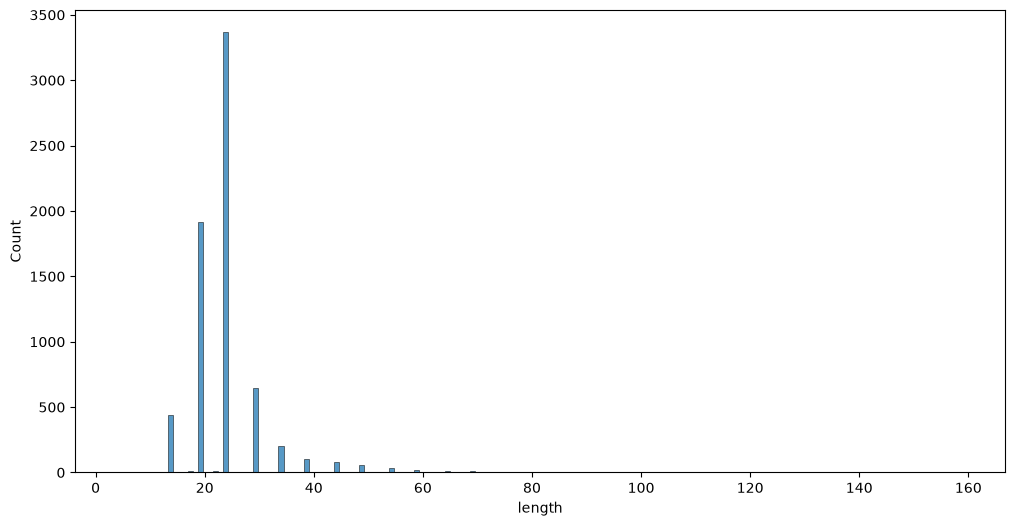

In [24]:
fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), sharex=True)
sns.histplot(data=POR_grouping_sub, x="length")

# Stats of the stacks

In [93]:
newGroupingDF = pd.read_parquet('lower_conf_thresh_0.1_0.05.parquet')
POR_grouping = pd.read_parquet('/home/sayakdg/ILIWorkflows/workflows/corrosion_detection/data-files/0AXVHCA77S1/'
                                'corrosion_detection/corrosion_v4.2/grouping/corrosion_v4.2_grouped.parquet')

In [94]:
newGroupingDF['bin_size'] = newGroupingDF['bin_size'].round(2)
newGroupingDF['avg_defect_prob'] = newGroupingDF['total_vol_prob']/newGroupingDF['length']

In [95]:
newGroupingDF[['length','bin_size']].groupby('bin_size').agg(['mean','max','min','std','count']).round(2)

length                      
           mean  max min   std  count
bin_size                             
0.10      12.28  200   5  5.82  28466
0.15      10.44   45   5  4.45  15801
0.20       9.55   45   5  3.97  10360
0.25       8.74   40   5  3.52   7309
0.30       8.30   30   5  3.16   5502
0.35       7.86   35   5  2.94   4395
0.40       7.54   25   5  2.84   3487
0.45       7.27   25   5  2.68   2867
0.50       7.06   20   5  2.60   2412
0.55       6.75   20   5  2.52   2039
0.60       6.57   20   5  2.45   1778
0.65       6.37   25   5  2.53   1602
0.70       6.20   20   5  2.37   1388
0.75       6.05   25   5  2.31   1284
0.80       6.04   26   5  2.37   1209
0.85       6.03   30   5  2.51   1136
0.90       6.33   40   5  3.23   1207
0.95       7.22   50   5  4.43    859

In [96]:
newGroupingDF[['vol_conf','bin_size']].groupby('bin_size').agg(['mean','max','min','std','count']).round(2)

vol_conf                         
             mean   max   min   std  count
bin_size                                  
0.10         0.12  0.37  0.10  0.02  28466
0.15         0.17  0.57  0.15  0.02  15801
0.20         0.22  0.55  0.20  0.02  10360
0.25         0.27  0.61  0.25  0.02   7309
0.30         0.32  0.58  0.30  0.02   5502
0.35         0.37  0.73  0.35  0.02   4395
0.40         0.42  0.84  0.40  0.02   3487
0.45         0.48  0.71  0.45  0.02   2867
0.50         0.53  0.70  0.50  0.02   2412
0.55         0.58  0.79  0.55  0.02   2039
0.60         0.63  0.83  0.60  0.02   1778
0.65         0.68  0.83  0.65  0.02   1602
0.70         0.73  0.85  0.70  0.02   1388
0.75         0.77  0.86  0.75  0.02   1284
0.80         0.83  0.95  0.80  0.02   1209
0.85         0.87  0.95  0.85  0.02   1136
0.90         0.93  0.97  0.90  0.01   1207
0.95         0.97  0.99  0.95  0.01    859

In [97]:
newGroupingDF[['avg_defect_prob','bin_size']].groupby('bin_size').agg(['mean','max','min','std','count']).round(2)

avg_defect_prob                         
                    mean   max   min   std  count
bin_size                                         
0.10                0.12  0.31  0.10  0.01  28466
0.15                0.17  0.48  0.15  0.01  15801
0.20                0.22  0.48  0.20  0.01  10360
0.25                0.27  0.46  0.25  0.01   7309
0.30                0.32  0.45  0.30  0.01   5502
0.35                0.37  0.48  0.35  0.01   4395
0.40                0.42  0.50  0.40  0.01   3487
0.45                0.47  0.60  0.45  0.01   2867
0.50                0.52  0.65  0.50  0.01   2412
0.55                0.57  0.69  0.55  0.01   2039
0.60                0.62  0.68  0.60  0.01   1778
0.65                0.67  0.76  0.65  0.01   1602
0.70                0.72  0.83  0.70  0.01   1388
0.75                0.77  0.81  0.75  0.01   1284
0.80                0.82  0.88  0.80  0.01   1209
0.85                0.87  0.91  0.85  0.01   1136
0.90                0.92  0.95  0.90  0.01   1207
0.95                0.97  0.99  0.95  0.01    859

<Axes: xlabel='bin_size', ylabel='avg_defect_prob'>

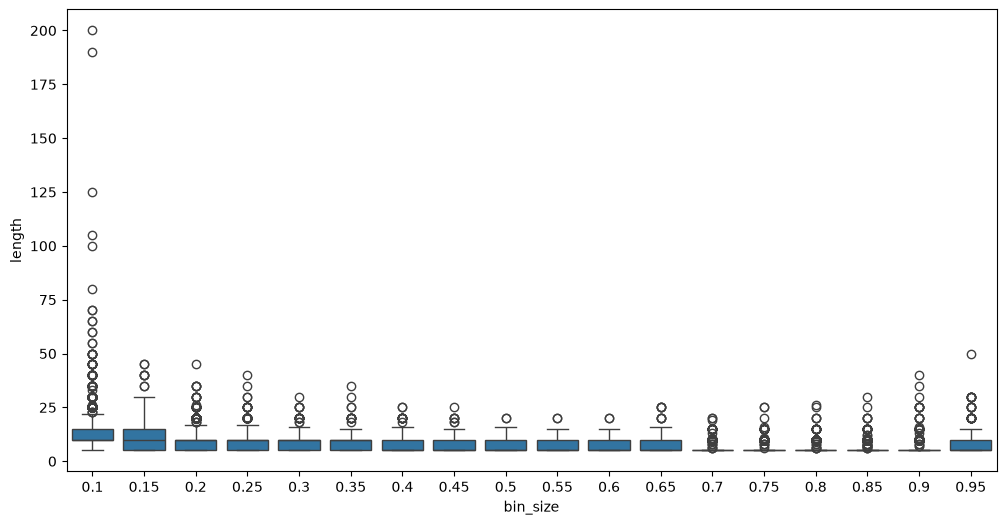

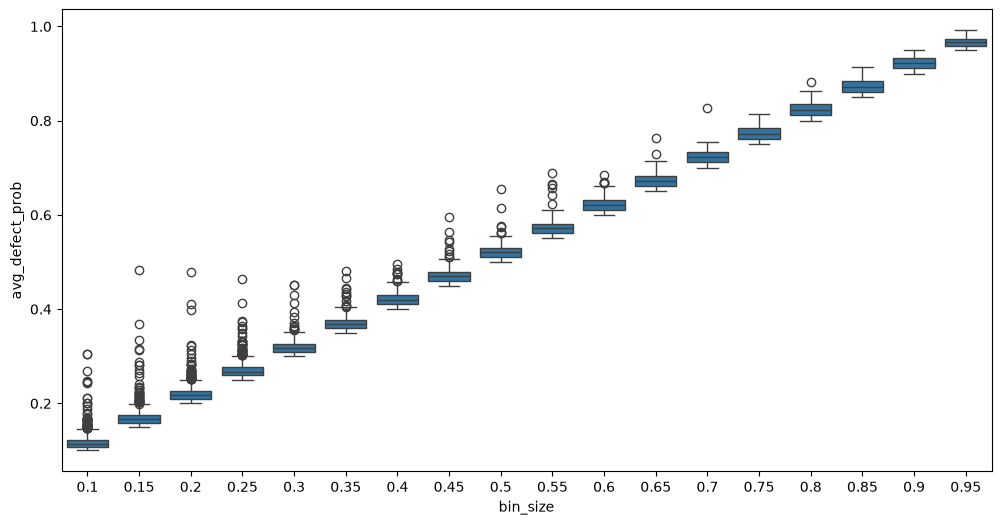

In [98]:
fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), sharex=True)
sns.boxplot(data=newGroupingDF, x="bin_size", y="length")

fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), sharex=True)
sns.boxplot(data=newGroupingDF, x="bin_size", y="avg_defect_prob")

<Axes: xlabel='vol_conf', ylabel='Count'>

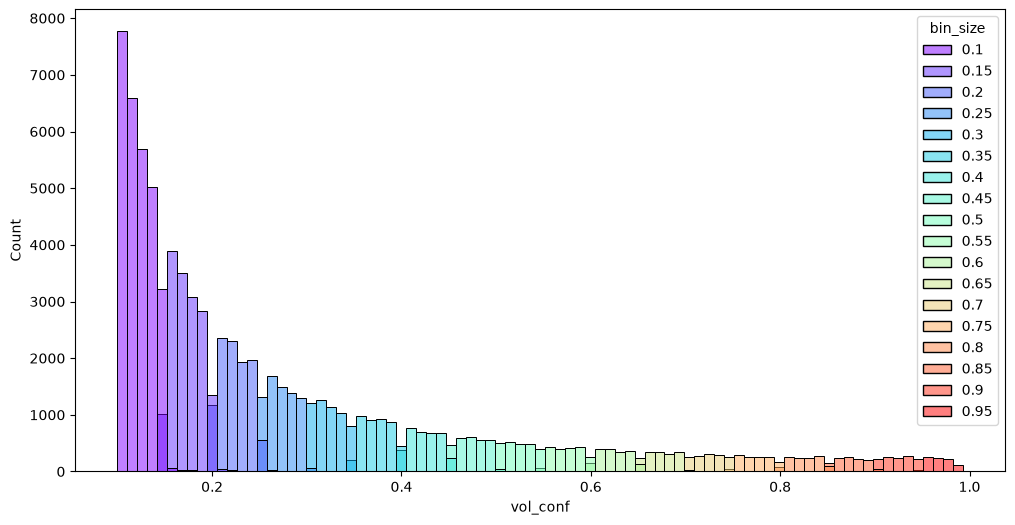

In [22]:
fig, ax1 = plt.subplots(1, 1, figsize=(12, 6), sharex=True)
sns.histplot(data=newGroupingDF, x="vol_conf", hue="bin_size",palette="rainbow")

In [ ]:
newGroupingDF.query('bin_size >= 0.9 and length > 50')

In [ ]:
newGroupingDF['bin_size'].unique()

# Filter for anomaly detection

In [80]:
filterGroupingDF = newGroupingDF.query('bin_size < 0.7').reset_index(drop = True)
filterGroupingDF

,clip_id,track_id,final_group_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,total_vol_prob,length,bin_size,anomaly_type
0,01-020-1B3U2VQS,20,0,109710030,109710192,6060904,6060913,0.295386,2.806221,10,0.25,ID_CORRO_POS
1,01-020-1B3U2VQS,20,0,1228071270,1228071450,67882394,67882403,0.549947,5.462166,10,0.50,ID_CORRO_POS
2,01-020-1B3U2VQS,20,0,509723244,509723406,28166994,28167003,0.189228,1.721905,10,0.15,ID_CORRO_POS
3,01-020-1B3U2VQS,20,1,509915124,509915376,28177654,28177668,0.142330,2.019332,15,0.10,ID_CORRO_POS
4,01-020-1B3U2VQS,20,2,510032484,510032646,28184174,28184183,0.110798,1.078677,10,0.10,ID_CORRO_POS
...,...,...,...,...,...,...,...,...,...,...,...,...
86013,01-001-1B3U2YV3,1,2,1555465302,1555465374,85965124,85965128,0.102844,0.514220,5,0.10,ID_CORRO_POS
86014,01-001-1B3U2YV3,1,0,1555479882,1555480134,85965934,85965948,0.342797,4.759829,15,0.30,ID_CORRO_POS
86015,01-001-1B3U2YV3,1,0,1624022898,1624023060,89756149,89756158,0.577478,5.686597,10,0.55,ID_CORRO_POS
86016,01-001-1B3U2YV3,1,1,1624222068,1624222410,89767214,89767233,0.144463,2.508895,20,0.10,ID_CORRO_POS


In [88]:
# use the bin probabilty to define sample size

def prob_binning(bin_label,confidence_level,error_margin_prob):
    # designed for a two sided CI
    alpha = 1 - confidence_level
    z_score = norm.ppf(1 - alpha / 2)
    sample_size = int(np.ceil((z_score**2.0)*bin_label*(1-bin_label)/error_margin_prob**2.0))
    return sample_size

In [92]:
# sample 100 points per bin
filterGroupingDF['avg_defect_prob'] = filterGroupingDF['total_vol_prob']/filterGroupingDF['length']
bins = filterGroupingDF['bin_size'].unique()
subSamplefilterGroupingDF = pd.DataFrame()
for bin_size in tqdm(bins):
    df = filterGroupingDF.query('bin_size == @bin_size')
    bin_count = len(df)
    sampling_size = prob_binning(bin_size,0.95,0.1)
    print('Bin and corresponding sample size:',bin_size,sampling_size)
    if bin_count >= sampling_size:
        sampled_df = df.sample(n=sampling_size, weights='avg_defect_prob')
    else:
        sampled_df = df.sample(n=bin_count)
    subSamplefilterGroupingDF = pd.concat([subSamplefilterGroupingDF,sampled_df]).reset_index(drop = True)
subSamplefilterGroupingDF

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [00:00<00:00, 53.23it/s]

Bin and corresponding sample size: 0.25 73
Bin and corresponding sample size: 0.5 97
Bin and corresponding sample size: 0.15 49
Bin and corresponding sample size: 0.1 35
Bin and corresponding sample size: 0.3 81
Bin and corresponding sample size: 0.55 96
Bin and corresponding sample size: 0.2 62
Bin and corresponding sample size: 0.6 93
Bin and corresponding sample size: 0.45 96
Bin and corresponding sample size: 0.35 88
Bin and corresponding sample size: 0.65 88
Bin and corresponding sample size: 0.4 93


,clip_id,track_id,final_group_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,total_vol_prob,length,bin_size,anomaly_type,avg_defect_prob
0,01-000-1B3U2QML,0,2,803897232,803897394,44429869,44429878,0.286592,2.796566,10,0.25,ID_CORRO_POS,0.279657
1,01-003-1B3U2S7P,3,0,667934334,667934496,36907424,36907433,0.297192,2.929661,10,0.25,ID_CORRO_POS,0.292966
2,01-013-1B3U3DTN,13,1,1536905034,1536905106,84945669,84945673,0.252222,1.261109,5,0.25,ID_CORRO_POS,0.252222
3,01-005-1B3U34PR,5,10,748342506,748342578,41373229,41373233,0.255623,1.278117,5,0.25,ID_CORRO_POS,0.255623
4,01-006-1B3U30M8,6,3,737723868,737724030,40778824,40778833,0.293003,2.905951,10,0.25,ID_CORRO_POS,0.290595
...,...,...,...,...,...,...,...,...,...,...,...,...,...
946,01-001-1B3U2YV3,1,2,863111868,863111940,47703504,47703508,0.425183,2.125915,5,0.40,ID_CORRO_POS,0.425183
947,01-013-1B3U3DTN,13,0,779397048,779397210,43068729,43068738,0.446489,4.444610,10,0.40,ID_CORRO_POS,0.444461
948,01-020-1B3U2VQS,20,0,150877776,150877938,8334804,8334813,0.447651,4.376268,10,0.40,ID_CORRO_POS,0.437627
949,01-017-1B3U2UAF,17,3,54906,54978,999,1003,0.439039,2.195193,5,0.40,ID_CORRO_POS,0.439039


In [91]:
np.sort(subSamplefilterGroupingDF['bin_size'].unique())

array([0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 , 0.55, 0.6 ,
       0.65])

In [41]:
# # write parquet for raw data out
# table = pa.Table.from_pandas(subSamplefilterGroupingDF)
# with pq.ParquetWriter('lower_conf_thresh_0.1_0.05_sub_samp_100_07.parquet', table.schema) as writer:
#     writer.write_table(table)

In [48]:
df = pd.read_parquet('/home/sayakdg/ILIWorkflows/workflows/corrosion_sizing/data-files/0AXVHCA77S1/corrosion_detection/corrosion_v4.2/grouping/corrosion_v4.2_grouped.parquet')
df['anomaly_type'] = "ID_CORRO_POS"
# df_sub = df[['clip_id', 'start_odo_ticks', 'end_odo_ticks', 'start_frame_idx','end_frame_idx', 'vol_conf']].reset_index(drop = True)
df

,clip_id,start_odo_ticks,end_odo_ticks,start_frame_idx,end_frame_idx,vol_conf,anomaly_type
0,01-003-1B3U2S7P,813749256,813749418,44964349,44964358,0.279237,ID_CORRO_POS
1,01-006-1B3U30M8,375967740,375967812,20780889,20780893,0.285750,ID_CORRO_POS
2,01-013-1B3U3DTN,285261066,285261228,15763739,15763748,0.267076,ID_CORRO_POS
3,01-011-1B3U2R5Y,213765564,213765636,11814364,11814368,0.265655,ID_CORRO_POS
4,01-006-1B3U30M8,232364838,232365000,12845079,12845088,0.287890,ID_CORRO_POS
...,...,...,...,...,...,...,...
1195,01-008-1B3U35Z7,442455660,442455822,24459464,24459473,0.445397,ID_CORRO_POS
1196,01-007-1B3U2ZJ8,253123110,253123272,13990819,13990828,0.442586,ID_CORRO_POS
1197,01-013-1B3U3DTN,1492135224,1492135386,82473744,82473753,0.440451,ID_CORRO_POS
1198,01-017-1B3U2UAF,1489738890,1489738962,82347184,82347188,0.408309,ID_CORRO_POS


In [49]:
table = pa.Table.from_pandas(df)
with pq.ParquetWriter('/home/sayakdg/ILIWorkflows/workflows/corrosion_sizing/data-files/0AXVHCA77S1/corrosion_detection/corrosion_v4.2/grouping/corrosion_v4.2_grouped.parquet', table.schema) as writer:
    writer.write_table(table)